In [2]:
import os
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.tree import DecisionTreeClassifier

from imblearn.pipeline import make_pipeline as imbl_pipe
from imblearn.over_sampling import SMOTE

In [4]:
# Load the dataset
file_path = "Churn_Modelling.csv"
data = pd.read_csv(file_path)

# Remove unnecessary columns
data = data.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

# Display the first few rows of the dataset
data.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## Models Training

## Let's start by splitting our dataframe into separate objects:

y for the target varibale

X for the input features

In [5]:
# Separate dataframe into separate objects
# Target variable
target_variable = data.Exited

# Input features
input_features = data.drop(['Exited'], axis=1)

# Display shapes of features and target
print(input_features.shape, target_variable.shape)

(10000, 10) (10000,)


In [6]:

# List numerical features
numerical_columns = input_features.select_dtypes(include='number').columns.tolist()
numerical_columns

['CreditScore',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary']

In [7]:
# List categorical features
categorical_columns = input_features.select_dtypes(include='object').columns.tolist()
categorical_columns

['Geography', 'Gender']

In [8]:
# Function to count classes in the target variable
def count_classes(data):
    counter = Counter(data)
    kv = [list(counter.keys()), list(counter.values())]
    data_counts = pd.DataFrame(np.array(kv).T, columns=['Exited', 'Count'])
    data_counts['Count'] = data_counts['Count'].astype('int64')
    data_counts['%'] = round(data_counts['Count'] / data.shape[0] * 100, 2)
    return data_counts.sort_values('Count', ascending=False)

In [9]:
count_classes(target_variable)

,Exited,Count,%
1,0,7963,79.63
0,1,2037,20.37


## Create a Train Test Split

We will continue with splitting our data into separate training and test sets.

30% of observations will be set aside for the test set

the rest, 70%, will be used as the training set

In [10]:
random_state = 10

# Split features (X) and target variable (y) into train and test sets
X_train, X_test, y_train, y_test = train_test_split(input_features, target_variable,
                                                    test_size=0.3,
                                                    random_state=random_state,
                                                    stratify=data.Exited)

# Print number of observations in X_train, X_test, y_train, and y_test
print(len(X_train), len(X_test), len(y_train), len(y_test))

7000 3000 7000 3000


In [11]:
# Information about the training data
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7000 entries, 8061 to 4741
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      7000 non-null   int64  
 1   Geography        7000 non-null   object 
 2   Gender           7000 non-null   object 
 3   Age              7000 non-null   int64  
 4   Tenure           7000 non-null   int64  
 5   Balance          7000 non-null   float64
 6   NumOfProducts    7000 non-null   int64  
 7   HasCrCard        7000 non-null   int64  
 8   IsActiveMember   7000 non-null   int64  
 9   EstimatedSalary  7000 non-null   float64
dtypes: float64(2), int64(6), object(2)
memory usage: 601.6+ KB


## Pre-processing Pipeline
 
 ## Scale numerical data and encode categorical data
Construct a pre-processing pipeline from the given transformers: MinMaxScaler and OneHotEncoder Create lists of indexes from the list of column namesNeed to be numeric not string to specify columns name in column transformer

In [12]:
# Index locations of numerical features
num_features = [] 

for column in numerical_columns:
    location = input_features.columns.get_loc(column)
    num_features.append(location)

print(num_features)

[0, 3, 4, 5, 6, 7, 8, 9]


In [13]:
# Index locations of categorical features
cat_features = []

for column in categorical_columns:
    location = input_features.columns.get_loc(column)
    cat_features.append(location)

print(cat_features)

[1, 2]


In [14]:
# Define column transformer
preprocess = make_column_transformer(
    (MinMaxScaler(), num_features),  # MinMaxScaler to numerical features
    (OneHotEncoder(), cat_features)  # OneHotEncoder to categorical features
)
preprocess

ColumnTransformer(transformers=[('minmaxscaler', MinMaxScaler(),
                                 [0, 3, 4, 5, 6, 7, 8, 9]),
                                ('onehotencoder', OneHotEncoder(), [1, 2])])

In [15]:
# Model with pipeline
model = imbl_pipe(preprocess,
                  SMOTE(sampling_strategy='auto', random_state=random_state),
                  DecisionTreeClassifier(random_state=random_state))
model

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('minmaxscaler',
                                                  MinMaxScaler(),
                                                  [0, 3, 4, 5, 6, 7, 8, 9]),
                                                 ('onehotencoder',
                                                  OneHotEncoder(), [1, 2])])),
                ('smote', SMOTE(random_state=10)),
                ('decisiontreeclassifier',
                 DecisionTreeClassifier(random_state=10))])

In [16]:
# Define parameter grid for Decision Tree classifier
dt_param_grid = {
    'decisiontreeclassifier__max_leaf_nodes': [2, 10, 20, 30],
    'decisiontreeclassifier__min_samples_split': [2, 3, 4],
    'decisiontreeclassifier__criterion': ['gini', 'entropy']
}

# GridSearchCV model
dt_grid = GridSearchCV(model, dt_param_grid, verbose=3, cv=5, scoring='accuracy')

In [17]:
# Convert X_train and X_test to numpy arrays
X_train = X_train.values
X_test = X_test.values


In [18]:
# Fit the model
dt_grid.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
[CV 1/5] END decisiontreeclassifier__criterion=gini, decisiontreeclassifier__max_leaf_nodes=2, decisiontreeclassifier__min_samples_split=2;, score=0.714 total time=   0.1s
[CV 2/5] END decisiontreeclassifier__criterion=gini, decisiontreeclassifier__max_leaf_nodes=2, decisiontreeclassifier__min_samples_split=2;, score=0.685 total time=   0.0s
[CV 3/5] END decisiontreeclassifier__criterion=gini, decisiontreeclassifier__max_leaf_nodes=2, decisiontreeclassifier__min_samples_split=2;, score=0.680 total time=   0.0s
[CV 4/5] END decisiontreeclassifier__criterion=gini, decisiontreeclassifier__max_leaf_nodes=2, decisiontreeclassifier__min_samples_split=2;, score=0.714 total time=   0.0s
[CV 5/5] END decisiontreeclassifier__criterion=gini, decisiontreeclassifier__max_leaf_nodes=2, decisiontreeclassifier__min_samples_split=2;, score=0.744 total time=   0.0s
[CV 1/5] END decisiontreeclassifier__criterion=gini, decisiontreeclassifier__m

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('columntransformer',
                                        ColumnTransformer(transformers=[('minmaxscaler',
                                                                         MinMaxScaler(),
                                                                         [0, 3,
                                                                          4, 5,
                                                                          6, 7,
                                                                          8,
                                                                          9]),
                                                                        ('onehotencoder',
                                                                         OneHotEncoder(),
                                                                         [1,
                                                                          2])])),
                                       ('smote', SMOTE(random_state=10)),
                                       ('decisiontreeclassifier',
                                        DecisionTreeClassifier(random_state=10))]),
             param_grid={'decisiontreeclassifier__criterion': ['gini',
                                                               'entropy'],
                         'decisiontreeclassifier__max_leaf_nodes': [2, 10, 20,
                                                                    30],
                         'decisiontreeclassifier__min_samples_split': [2, 3,
                                                                       4]},
             scoring='accuracy', verbose=3)

In [19]:
# Best parameters and best score
print(dt_grid.best_params_)
print(dt_grid.best_score_)

{'decisiontreeclassifier__criterion': 'entropy', 'decisiontreeclassifier__max_leaf_nodes': 30, 'decisiontreeclassifier__min_samples_split': 2}
0.8130000000000001


In [20]:
# Scores on training and testing data
print(f"Training Data Score: {dt_grid.score(X_train, y_train)}")
print(f"Testing Data Score: {dt_grid.score(X_test, y_test)}")

Training Data Score: 0.805
Testing Data Score: 0.7973333333333333


In [21]:
# Predictions on the test set
predictions = dt_grid.predict(X_test)


In [22]:
# First 10 predictions and actual labels
print(f"First 10 Predictions:   {predictions[:10]}")
print(f"First 10 Actual labels: {y_test[:10].tolist()}")

First 10 Predictions:   [0 0 0 0 0 1 0 0 0 1]
First 10 Actual labels: [1, 0, 0, 0, 0, 1, 0, 0, 0, 0]


In [23]:
pd.DataFrame({"Prediction": predictions, "Actual": y_test}).reset_index(drop=True)

,Prediction,Actual
0,0,1
1,0,0
2,0,0
3,0,0
4,0,0
...,...,...
2995,1,0
2996,0,0
2997,1,0
2998,0,0


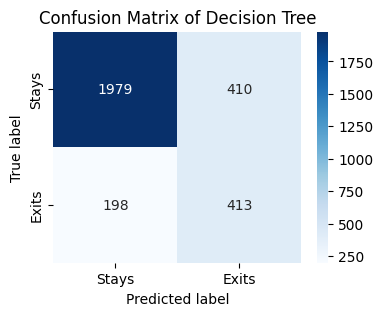

In [24]:
# Confusion Matrix
cm = confusion_matrix(y_test, predictions)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='g', 
            xticklabels=['Stays', 'Exits'], 
            yticklabels=['Stays', 'Exits'])
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix of Decision Tree')
plt.show()

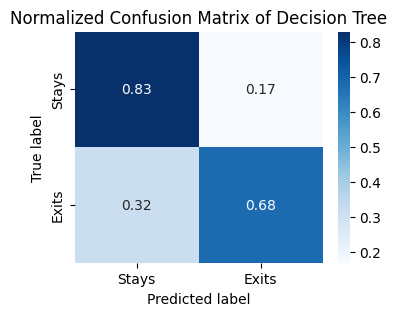

In [25]:
# Normalized Confusion Matrix
cm_normalized = np.around(cm / cm.sum(axis=1)[:, np.newaxis], 2)
plt.figure(figsize=(4, 3))
sns.heatmap(cm_normalized, annot=True, cmap='Blues', 
            xticklabels=['Stays', 'Exits'], 
            yticklabels=['Stays', 'Exits'])
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Normalized Confusion Matrix of Decision Tree')
plt.show()


In [26]:
# Classification Report
report = classification_report(y_test, predictions)
print(report)


              precision    recall  f1-score   support

           0       0.91      0.83      0.87      2389
           1       0.50      0.68      0.58       611

    accuracy                           0.80      3000
   macro avg       0.71      0.75      0.72      3000
weighted avg       0.83      0.80      0.81      3000



In [27]:
# Predicted class for a single sample
pred = dt_grid.predict(X_test[:1])
print(f"Predicted classes: {pred}")
print(f"Actual Labels: {list(y_test[:1])}")

Predicted classes: [0]
Actual Labels: [1]


In [29]:
import joblib

filename = 'decision_tree.sav'
joblib.dump(dt_grid, filename)

['decision_tree.sav']

In [30]:
dt_model = joblib.load(filename)
print(dt_model.score(X_test, y_test))

0.7973333333333333
